# Partie 2 — Régression avec SVR (Support Vector Regression)

## Objectif

Dans la partie précédente, on a discrétisé mpg en 3 classes (faible/moyenne/élevée) pour traiter le problème comme une **classification**. 

Contrairement à la classification, la variable cible mpg conserve ici sa nature continue. L'objectif est de prédire une valeur numérique aussi proche que possible de la consommation réelle.


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVR

from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

Chargement du dataset

In [3]:
df = sns.load_dataset("mpg")

print(df.head())
print(df.shape)
print(df.info())

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
(398, 9)
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   

Vérification des valeurs manquantes

In [4]:
print(df.isnull().sum())

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


### Suppression des valeurs manquantes.

Dans notre dataset, la variable horsepower contient des valeurs manquantes. Comme nous en avons très peu, nous pouvons utiliser la même stratégie que dans la classification : supprimer les observations concernées.

In [7]:
df = df.dropna()

print("Shape",df.shape)

Shape (392, 9)


## Préparation des variables

Nous séparons les caractéristiques des véhicules de la variable cible 'mpg'.

La variable cible conserve ses valeurs numériques afin de réaliser une prédiction continue.

La colonne 'name' est supprimée, car elle représente le nom du véhicule et n'est pas utilisée dans notre modèle.

In [8]:
X = df.drop(columns=["mpg", "name"])
y = df["mpg"]

Comme dans la classification, nous utilisons One-Hot Encoding pour transformer origin.

In [9]:
X = pd.get_dummies(X, columns=["origin"], dtype=int)

print(X.head())

   cylinders  displacement  horsepower  weight  acceleration  model_year  \
0          8         307.0       130.0    3504          12.0          70   
1          8         350.0       165.0    3693          11.5          70   
2          8         318.0       150.0    3436          11.0          70   
3          8         304.0       150.0    3433          12.0          70   
4          8         302.0       140.0    3449          10.5          70   

   origin_europe  origin_japan  origin_usa  
0              0             0           1  
1              0             0           1  
2              0             0           1  
3              0             0           1  
4              0             0           1  


## Séparation des données

Nous divisons le dataset en deux parties :

- 80 % des observations pour l'entraînement.
- 20 % des observations pour le test.

Cette séparation permet d'évaluer les performances du modèle sur des données qu'il n'a pas utilisées pendant son apprentissage.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("X_train Shape :", X_train.shape)
print("X_test Shape:", X_test.shape)

X_train Shape : (313, 9)
X_test Shape: (79, 9)


### Standardisation

La standardisation est importante pour le SVR, car les caractéristiques possèdent des échelles différentes. Elle permet d'éviter qu'une variable ayant de grandes valeurs domine les autres

In [12]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Entraînement du modèle SVR linéaire

In [13]:
svr_model = SVR(kernel="linear", C=1.0, epsilon=0.1)

svr_model.fit(X_train, y_train)

y_pred = svr_model.predict(X_test)

Évaluation du modèle

In [14]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE :", rmse)
print("R2 :", r2)

MAE : 2.378723399823207
MSE : 11.32066030149876
RMSE : 3.364618893946053
R2 : 0.7782027637047705


### Interprétation

Le modèle SVR avec un noyau linéaire obtient un coefficient de détermination R² de 0.778, ce qui signifie qu'il explique environ 77.8 % de la variabilité de la consommation des véhicules. L'erreur absolue moyenne (MAE) est d'environ 2.38 MPG, tandis que la RMSE est de 3.36 MPG. Ces résultats montrent que le modèle réalise des prédictions relativement satisfaisantes, mais qu'il existe encore un écart entre certaines valeurs prédites et les valeurs réelles.

## Étudier l'influence du paramètre epsilon

Maintenant, on va tester plusieurs valeurs de epsilon pour observer leur influence sur :
- La qualité des prédictions.
- Le nombre de vecteurs de support utilisés par le modèle.


In [15]:
epsilon_values = [0.1, 0.5, 1, 2, 5]

results = []

for eps in epsilon_values:

    model = SVR(kernel="linear", C=1.0, epsilon=eps)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    nb_sv = len(model.support_)

    results.append([eps, mae, rmse, r2, nb_sv])

results_df = pd.DataFrame(
    results,
    columns=["Epsilon", "MAE", "RMSE", "R2", "Nombre de vecteurs de support"]
)

print(results_df)

   Epsilon       MAE      RMSE        R2  Nombre de vecteurs de support
0      0.1  2.378723  3.364619  0.778203                            304
1      0.5  2.352371  3.351844  0.779884                            272
2      1.0  2.370536  3.364239  0.778253                            229
3      2.0  2.382679  3.277689  0.789516                            157
4      5.0  2.521100  3.327794  0.783031                             38


Visualiser l'influence de epsilon

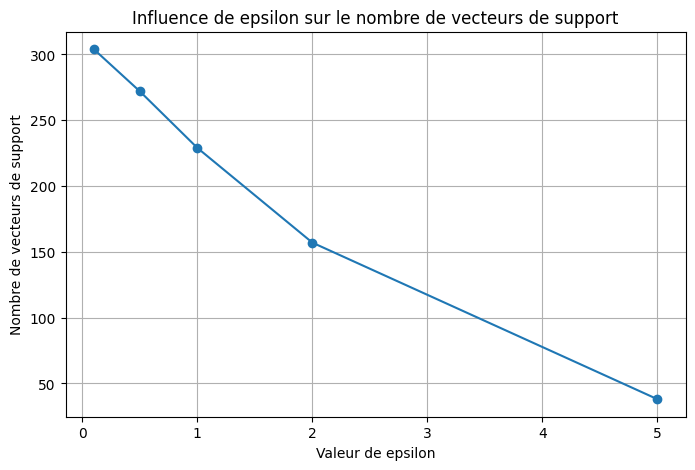

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Epsilon"],
    results_df["Nombre de vecteurs de support"],
    marker="o"
)

plt.xlabel("Valeur de epsilon")
plt.ylabel("Nombre de vecteurs de support")
plt.title("Influence de epsilon sur le nombre de vecteurs de support")
plt.grid()
plt.show()

### Analyse de l'influence du paramètre epsilon

Les résultats montrent que le nombre de vecteurs de support diminue lorsque la valeur de `epsilon` augmente. En effet, il passe de 304 pour `epsilon = 0.1` à seulement 38 pour `epsilon = 5`.

Cette diminution s'explique par l'élargissement de la zone de tolérance autour de la fonction de prédiction. Ainsi, davantage de données sont considérées comme suffisamment proches des prédictions et ne participent pas à la pénalisation de l'erreur.

Concernant les performances, elles restent relativement stables pour les différentes valeurs testées. La meilleure valeur de R² est obtenue avec `epsilon = 2`, soit environ 0.79. La MAE la plus faible est obtenue avec `epsilon = 0.5`, soit environ 2.35.

On remarque donc qu'une augmentation de `epsilon` permet de réduire le nombre de vecteurs de support, mais qu'une valeur trop élevée peut diminuer la précision des prédictions. Le choix de `epsilon` représente ainsi un compromis entre la tolérance aux erreurs et la qualité du modèle.

# SVR linéaire sans scikit learn

In [20]:
class SVR_Linear:

    def __init__(self, learning_rate=0.001, epochs=1000, C=1.0, epsilon=0.1):
        self.lr = learning_rate
        self.epochs = epochs
        self.C = C
        self.epsilon = epsilon

    def fit(self, X, y):

        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0

        for epoch in range(self.epochs):

            for i in range(n_samples):

                prediction = np.dot(X[i], self.w) + self.b
                error = prediction - y.iloc[i]

                if error > self.epsilon:
                    self.w -= self.lr * (self.w + self.C * X[i])
                    self.b -= self.lr * self.C

                elif error < -self.epsilon:
                    self.w -= self.lr * (self.w - self.C * X[i])
                    self.b += self.lr * self.C

                else:
                    self.w -= self.lr * self.w

    def predict(self, X):

        return np.dot(X, self.w) + self.b

Entraînement du modèle

In [21]:
my_svr = SVR_Linear(learning_rate=0.001,epochs=1000,C=1.0,epsilon=0.1)

my_svr.fit(X_train, y_train)

y_pred_custom = my_svr.predict(X_test)

Evaluation du modele

In [22]:
mae_custom = mean_absolute_error(y_test, y_pred_custom)
mse_custom = mean_squared_error(y_test, y_pred_custom)
rmse_custom = np.sqrt(mse_custom)
r2_custom = r2_score(y_test, y_pred_custom)

print("MAE :", mae_custom)
print("MSE :", mse_custom)
print("RMSE :", rmse_custom)
print("R2 :", r2_custom)

MAE : 3.4189539768416455
MSE : 21.341820453552625
RMSE : 4.619720819871329
R2 : 0.5818656625991779


On rq que notre modèle SVR personnalisé obtient une MAE de 3.42 et un coefficient R² de 0.582.

En comparaison avec le modèle de scikit-learn, qui obtient une MAE de 2.38 et un R² de 0.778, notre implémentation présente des performances inférieures.

Cette différence peut s'expliquer par la simplicité de notre méthode d'optimisation, qui utilise une descente de gradient élément par élément. L'implémentation de scikit-learn utilise une méthode d'optimisation plus adaptée au problème SVR.

Malgré cette différence, notre implémentation permet de comprendre le principe de la marge epsilon et l'influence des erreurs sur la mise à jour des paramètres du modèle.